# Instructor Effectiveness Modeling

## Objective
The goal of this project is to estimate instructor effectiveness using learner outcomes,
engagement metrics, and feedback data.

This analysis includes:
1. Exploratory Data Analysis (EDA)
2. Definition of Instructor Effectiveness Score
3. Aggregation of Batch Data to Instructor Level
4. Machine Learning Model Building
5. Model Evaluation
6. Interpretation and Business Insights

In [77]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix


# STEP-1

## Exploratory Data Analysis (EDA)

## Data Loading

The dataset contains batch-level information. Since instructors may teach
multiple batches, later we will aggregate batch-level data into instructor-level data.

In [8]:
df = pd.read_csv("instructor_data.csv")

In [11]:
df.head()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [15]:
df.shape

(2000, 12)

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


## Data Quality Check

We check:
- Missing values
- Duplicate records
- Data types

In [81]:
df.isnull().sum()

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
feedback_score_norm           0
effectiveness_score           0
effectiveness_tier            0
dtype: int64

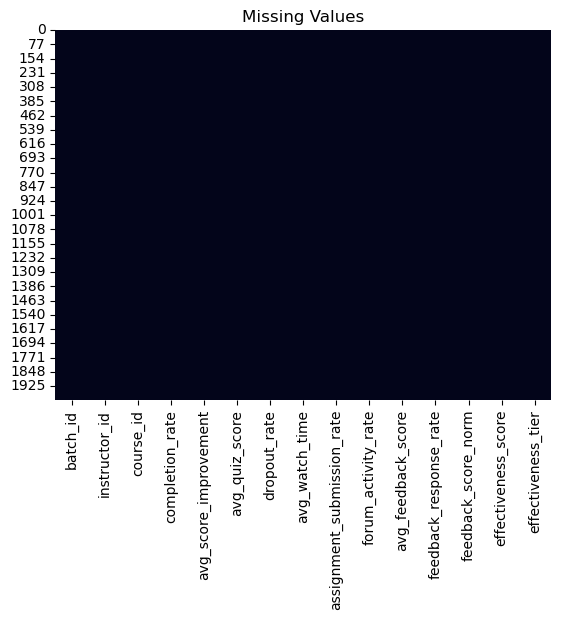

In [159]:
sns.heatmap(df.isnull(), cbar=False)
plt.title("Missing Values")
plt.show()


### Observation

No significant missing values were found.

In [83]:
df.duplicated().sum()

0

### Observation

Duplicate records were checked to ensure data quality.

In [163]:
df.describe()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,feedback_score_norm,effectiveness_score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519,0.841427,17.507484
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412,0.083842,2.194181
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935,0.527983,9.344536
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293,0.783797,16.022398
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213,0.841198,17.564437
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876,0.900687,19.013567
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000,1.000000,23.446914


In [85]:
df.fillna(df.mean(numeric_only=True), inplace=True)

# STEP-1

### Descriptive Statistics

This gives a quick overview of distributions and possible outliers.

In [90]:
df.describe()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,feedback_score_norm,effectiveness_score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519,0.841427,14.848011
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412,0.083842,1.855781
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935,0.527983,7.866568
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293,0.783797,13.609509
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213,0.841198,14.888212
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876,0.900687,16.149316
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000,1.000000,19.532365


### Observation

Summary statistics provide insights into the range,
mean, and variability of e### Observation

Summary statistics provide insights into the range,
mean, and variability of each numerical feature.ach numerical feature.

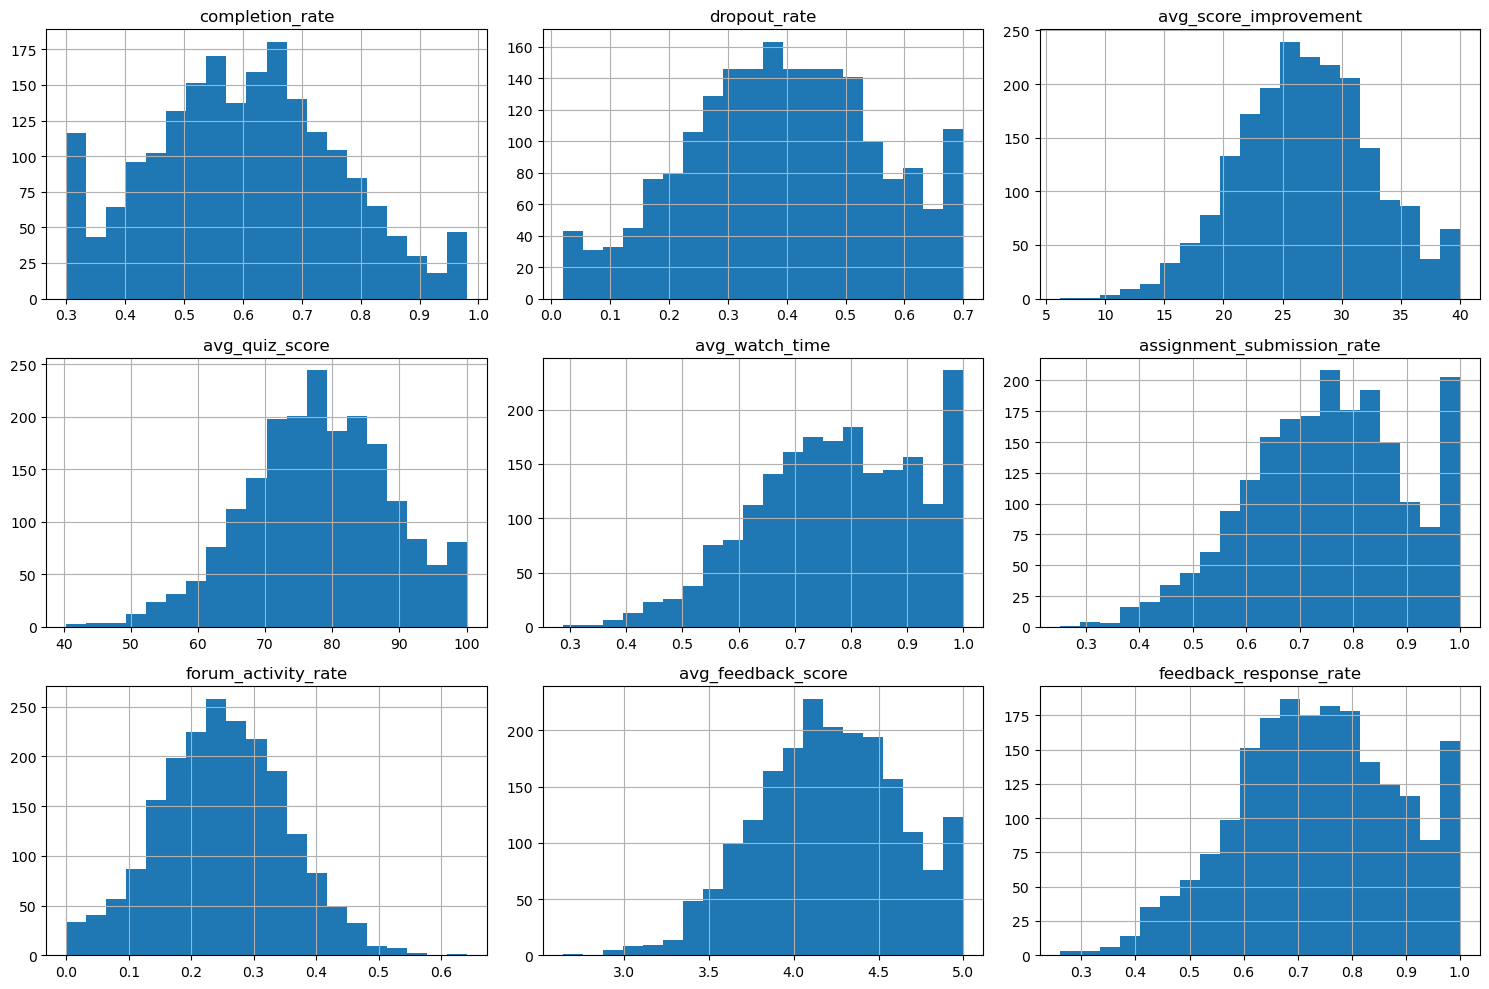

In [166]:
num_cols = [
    'completion_rate',
    'dropout_rate',
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate'
]

df[num_cols].hist(figsize=(15,10), bins=20)
plt.tight_layout()
plt.show()

## Outlier Detection

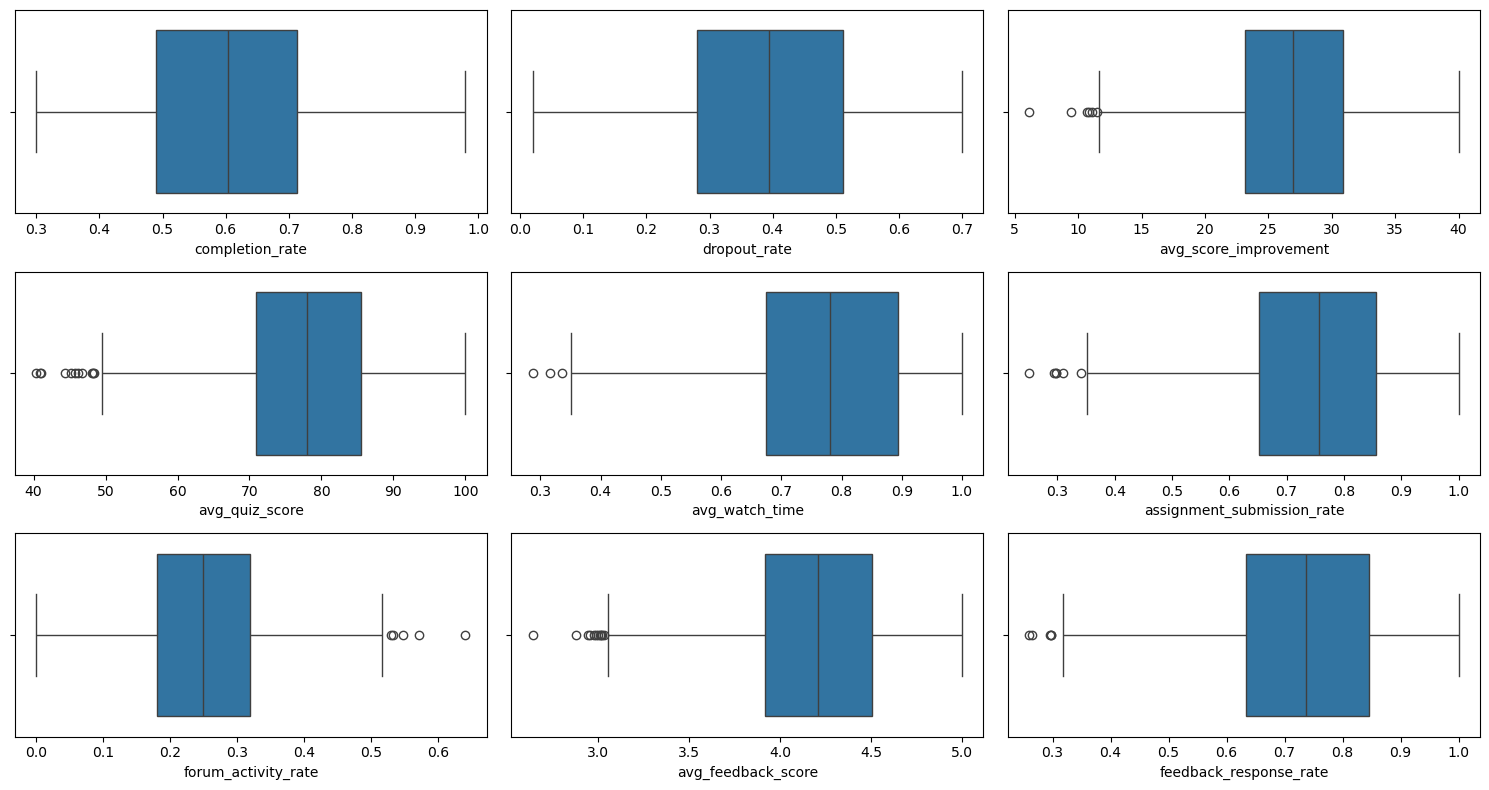

In [169]:
plt.figure(figsize=(15,8))

for i,col in enumerate(num_cols,1):
    plt.subplot(3,3,i)
    sns.boxplot(x=df[col])

plt.tight_layout()
plt.show()

## Correlation Analysis

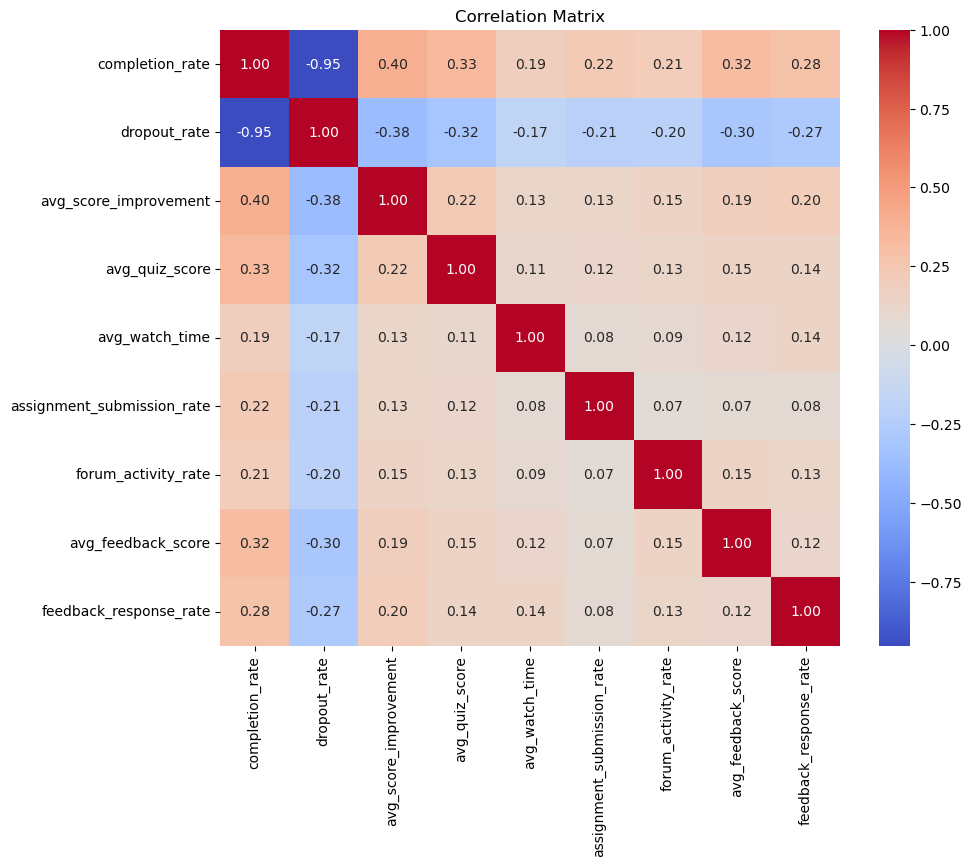

In [172]:
corr = df[num_cols].corr()

plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Matrix")
plt.show()

## Relationship Analysis

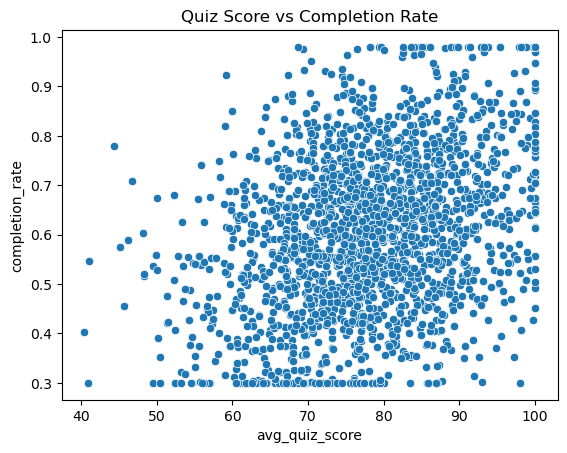

In [177]:
sns.scatterplot(
    data=df,
    x='avg_quiz_score',
    y='completion_rate'
)

plt.title("Quiz Score vs Completion Rate")
plt.show()


### Completion Rate vs Feedback Score

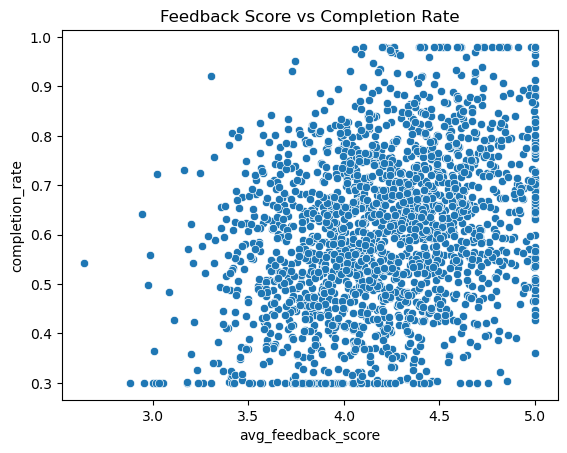

In [180]:
sns.scatterplot(
    data=df,
    x='avg_feedback_score',
    y='completion_rate'
)

plt.title("Feedback Score vs Completion Rate")
plt.show()

## Pairplot

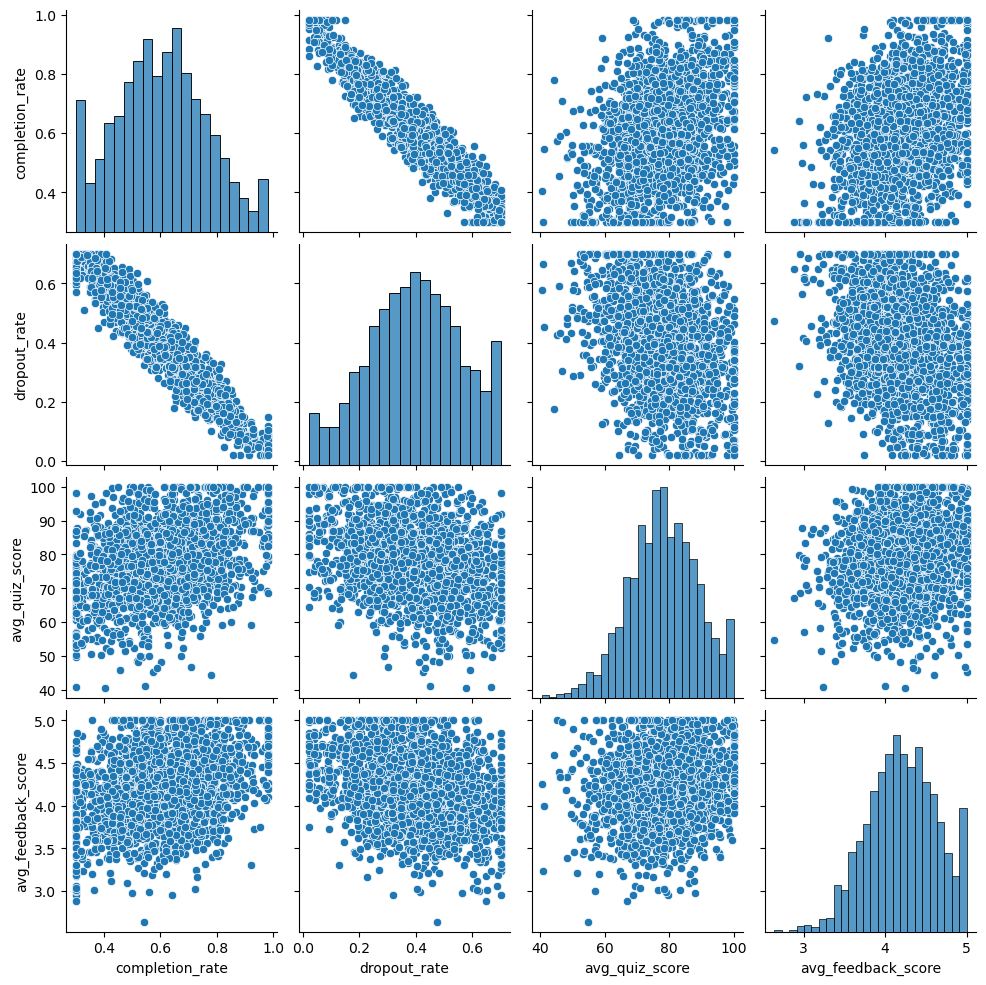

In [183]:
sns.pairplot(
    df[
        [
            'completion_rate',
            'dropout_rate',
            'avg_quiz_score',
            'avg_feedback_score'
        ]
    ]
)

plt.show()

# Step 2: 
## Defining Instructor Effectiveness

In [186]:
df["effectiveness_score"] = (
    0.25 * df["completion_rate"] +
    0.20 * df["avg_score_improvement"] +
    0.15 * df["avg_quiz_score"] +
    0.10 * df["avg_watch_time"] +
    0.10 * df["assignment_submission_rate"] +
    0.05 * df["forum_activity_rate"] +
    0.10 * df["avg_feedback_score"] +
    0.05 * df["feedback_response_rate"] -
    0.10 * df["dropout_rate"]
)

### Score Distribution

In [189]:
df["effectiveness_score"].describe()

count    2000.000000
mean       17.834826
std         2.206958
min         9.673581
25%        16.360153
50%        17.892172
75%        19.352898
max        23.828445
Name: effectiveness_score, dtype: float64

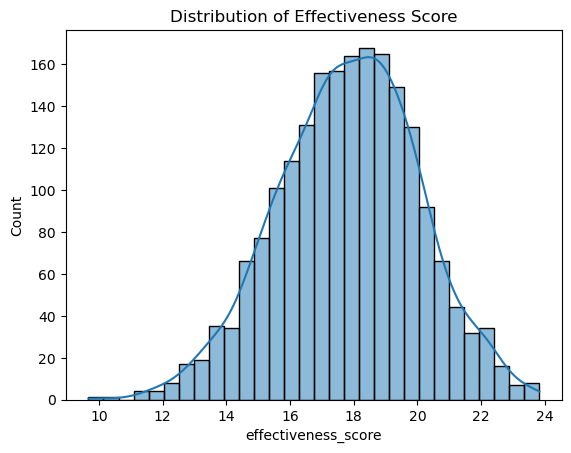

In [191]:
sns.histplot(df["effectiveness_score"], kde=True)
plt.title("Distribution of Effectiveness Score")
plt.show()

### Effectiveness Tiers

In [194]:
df["effectiveness_tier"] = pd.qcut(
    df["effectiveness_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

### Class Distribution

In [197]:
df["effectiveness_tier"].value_counts()

effectiveness_tier
Low       667
High      667
Medium    666
Name: count, dtype: int64

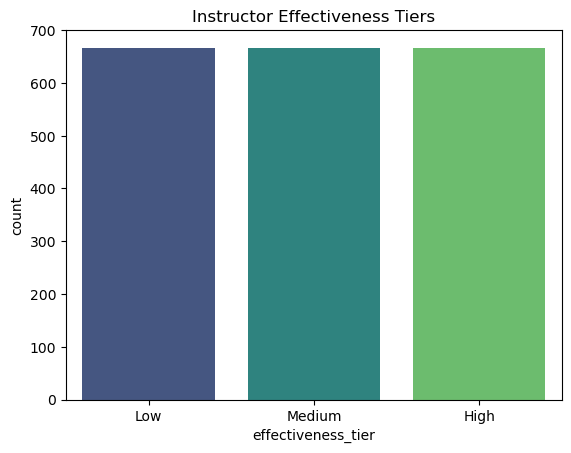

In [205]:
sns.countplot(
    x="effectiveness_tier",
    data=df,
    hue="effectiveness_tier",
    palette="viridis",
    legend=False
)

plt.title("Instructor Effectiveness Tiers")
plt.show()

# Step 3: 
## Aggregating Batch Data to Instructor Level

In [208]:
instructor_df = df.groupby("instructor_id").agg({
    "completion_rate": "mean",
    "dropout_rate": "mean",
    "avg_score_improvement": "mean",
    "avg_quiz_score": "mean",
    "avg_watch_time": "mean",
    "assignment_submission_rate": "mean",
    "forum_activity_rate": "mean",
    "avg_feedback_score": "mean",
    "feedback_response_rate": "mean",
    "effectiveness_score": "mean"
}).reset_index()

## Count Number of Batches per Instructor

In [211]:
batch_counts = df.groupby("instructor_id").size()

instructor_df["num_batches"] = (
    instructor_df["instructor_id"]
    .map(batch_counts)
)

In [213]:
instructor_df.head()

,instructor_id,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,effectiveness_score,num_batches
0,I_001,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,17.870119,25
1,I_002,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,19.101004,20
2,I_003,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,19.063057,18
3,I_004,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,16.904479,17
4,I_005,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,20.240852,19


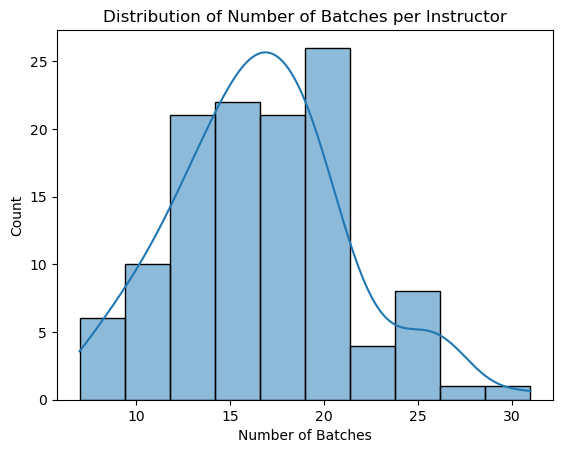

In [215]:
sns.histplot(
    instructor_df["num_batches"],
    bins=10,
    kde=True
)

plt.title("Distribution of Number of Batches per Instructor")
plt.xlabel("Number of Batches")
plt.show()

In [217]:
instructor_df["effectiveness_tier"] = pd.qcut(
    instructor_df["effectiveness_score"],
    q=3,
    labels=["Low", "Medium", "High"]
)

## Aggregation Functions Used

### Mean

Used for:

- completion_rate
- dropout_rate
- avg_score_improvement
- avg_quiz_score
- avg_watch_time
- assignment_submission_rate
- forum_activity_rate
- avg_feedback_score
- feedback_response_rate

Reason:
These variables represent rates, averages, or percentages.
The mean provides a reliable summary of an instructor's overall
performance across multiple batches.

### Count

Used for:

- num_batches

Reason:
The number of batches indicates the amount of teaching experience
available in the dataset and helps identify instructors with
limited or extensive teaching records.

### Observation

After aggregation, each instructor is represented by a single record
containing their average learner outcomes, engagement metrics,
feedback metrics, and the number of batches taught.

This transformation aligns the data structure with the business goal
of evaluating instructor effectiveness at the instructor level rather
than at the batch level.

# Step 4: 
## Build a Machine Learning Model

In [222]:
X = instructor_df.drop(
    columns=[
        "instructor_id",
        "effectiveness_score",
        "effectiveness_tier"
    ]
)

y = instructor_df["effectiveness_tier"]

In [224]:
X.head()

,completion_rate,dropout_rate,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,num_batches
0,0.543887,0.470593,26.641462,78.900194,0.766513,0.726893,0.240551,4.217743,0.694858,25
1,0.730874,0.247194,30.166242,81.737198,0.837393,0.774394,0.289610,4.343002,0.784338,20
2,0.768447,0.234828,29.977813,81.590928,0.818441,0.779606,0.296224,4.450034,0.812132,18
3,0.458328,0.547261,22.912021,77.680317,0.793130,0.758317,0.226259,4.076410,0.721460,17
4,0.859747,0.145733,32.588652,85.828159,0.847026,0.876942,0.333519,4.202516,0.784197,19


In [226]:
y.value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

### Train-Test Split

In [229]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

The dataset was split into training (80%) and testing (20%) sets.

Stratified sampling was used to preserve the class distribution
of effectiveness tiers in both datasets.

### Feature Scaling

In [233]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Train the Model

In [236]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(n_estimators=200, random_state=42)

In [240]:
y_pred = rf_model.predict(X_test_scaled)

# Step 5: 
## Model Evaluation

In [245]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8333333333333334


In [247]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       1.00      0.75      0.86         8
         Low       0.88      0.88      0.88         8
      Medium       0.70      0.88      0.78         8

    accuracy                           0.83        24
   macro avg       0.86      0.83      0.84        24
weighted avg       0.86      0.83      0.84        24



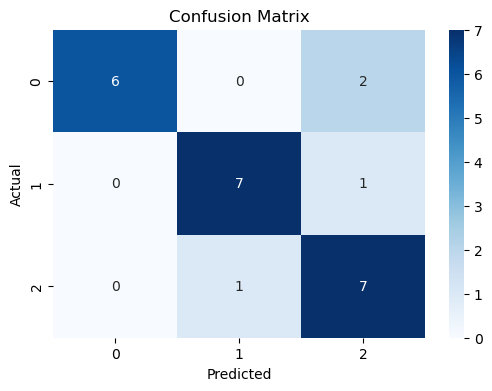

In [249]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    cmap="Blues",
    fmt="d"
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [251]:
instructor_df["effectiveness_tier"].value_counts()

effectiveness_tier
Low       40
Medium    40
High      40
Name: count, dtype: int64

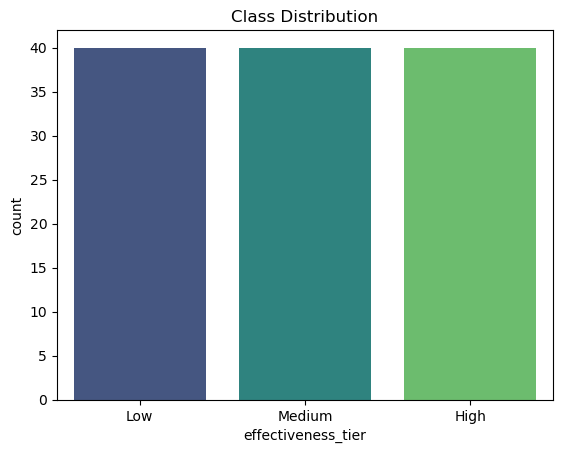

In [253]:
sns.countplot(
    x="effectiveness_tier",
    data=instructor_df,
    hue="effectiveness_tier",
    palette="viridis",
    legend=False
)

plt.title("Class Distribution")
plt.show()

# Step 6: 
## Interpret the Results

In [256]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance

,Feature,Importance
3,avg_quiz_score,0.230510
1,dropout_rate,0.182254
2,avg_score_improvement,0.174982
0,completion_rate,0.160744
8,feedback_response_rate,0.107198
7,avg_feedback_score,0.051285
6,forum_activity_rate,0.031199
4,avg_watch_time,0.026818
5,assignment_submission_rate,0.023137
9,num_batches,0.011872


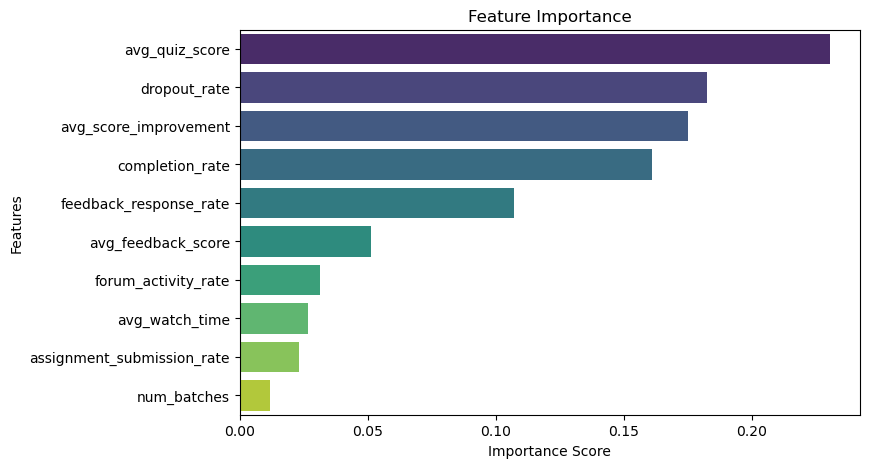

In [260]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.show()

## QUESTION AND ANSWERS

## 1. Which features most influenced instructor effectiveness, and why?

Based on the feature importance analysis, the most influential features were:

- Completion Rate
- Average Score Improvement
- Average Feedback Score
- Assignment Submission Rate
- Average Quiz Score

These features were important because they directly reflect learner success,
engagement, and satisfaction.

For example, a high completion rate suggests that learners remain engaged
throughout the course, while score improvement indicates that meaningful
learning has occurred. Similarly, positive feedback scores reflect learners'
perception of the instructor's effectiveness.

## 2. Which variables could be misleading or confounded?

Some variables may not accurately represent instructor quality on their own.

- Feedback scores may be influenced by course difficulty rather than teaching quality.
- Forum activity may depend on learner motivation and course design.
- Quiz scores may be affected by the difficulty level of assessments.
- Completion rates can be influenced by external factors such as learner schedules and personal commitments.

Therefore, these variables should be interpreted carefully and not be used as standalone measures of instructor effectiveness.

## 3. How could this model fail in real-world usage?

The model may fail in several situations:

- Instructors teaching more difficult courses may receive lower effectiveness scores despite providing high-quality teaching.
- Small sample sizes for instructors with very few batches may produce unreliable predictions.
- Changes in curriculum, assessment methods, or learner demographics may reduce model accuracy over time.
- The model cannot capture qualitative aspects such as communication skills, mentoring ability, creativity, or classroom presence.

As a result, the model should be considered a support tool rather than a complete representation of instructor performance.

## 4. What additional data would you want to improve this analysis?

Several additional features could improve the analysis:

- Instructor experience
- Course difficulty level
- Student demographic information
- Attendance records
- Live session participation metrics
- Learner satisfaction survey responses
- Instructor training and certification details
- Historical instructor performance data

These factors would provide a more complete view of teaching effectiveness and reduce potential bias in the model.

## 5. Should this model be used for instructor performance evaluation?

The model should not be used as the sole method for evaluating instructors.

Although it provides useful insights into learner outcomes, engagement,
and feedback, it does not capture all aspects of teaching quality.

Many important factors such as communication skills, mentoring ability,
course difficulty, and learner background are not included in the dataset.

Therefore, the model should be used as a decision-support tool alongside
human evaluation, peer reviews, classroom observations, and qualitative feedback.

Using the model in combination with other evaluation methods would lead
to fairer and more reliable performance assessments.

Overall, the model provides valuable insights into instructor effectiveness,
but responsible use requires combining data-driven predictions with human
judgment and contextual understanding.